# Stories Café: Impact of the 2026 Lebanon War, by Branch

**Question:** how did the war in Lebanon affect sales, customers and behavior at each branch (Harbour, Garden, Uptown)?

**Periods compared** (set in the first code cell, so they are easy to change):

| Period | Dates | Why |
|---|---|---|
| Before the war | Jan 1 to Feb 28, 2026 | Baseline |
| War | Mar 1 to Apr 15, 2026 | Fighting began on Mar 2. A US-brokered cessation of hostilities took effect on Apr 16 |
| After the ceasefire | Apr 16 to Jun 30, 2026 | Truce extended several times, though Israeli airstrikes continued |

**Note on the end date:** there is no single clear "end of the war". The Apr 16 cessation of hostilities was temporary and extended several times. Airstrikes continued after it, and a conditional Israel–Lebanon ceasefire was announced on Jun 4. This notebook uses Apr 16 as the end of active war. To test another end date, change `WAR_END` below and re-run.

Sources: [2026 Lebanon war](https://en.wikipedia.org/wiki/2026_Lebanon_war), [2026 Israel–Lebanon ceasefire](https://en.wikipedia.org/wiki/2026_Israel%E2%80%93Lebanon_ceasefire), [Al Jazeera, Jun 4 2026](https://www.aljazeera.com/news/2026/6/4/israel-and-lebanon-agree-to-conditional-ceasefire), [NPR, Jun 4 2026](https://www.npr.org/2026/06/04/g-s1-125942/israel-lebanon-ceasefire)

**Sections**
1. Setup and period definitions
2. Headline comparison by branch (per day, so periods of different length are comparable)
3. Daily orders by branch
4. Trend-adjusted effect by branch: did the war push sales below where they were heading?
5. Behavior by branch: time of day, dine-in vs takeaway, product mix
6. Customers by branch
7. Conclusion by branch

## 1. Setup and period definitions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

# --- Period boundaries: change these to test other definitions ---
WAR_START = pd.Timestamp("2026-03-01")
WAR_END = pd.Timestamp("2026-04-15")   # last day before the Apr 16 cessation of hostilities
PERIODS = ["Before the war", "War", "After the ceasefire"]

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Each branch keeps the same color as in 01_eda; periods are ordered, so they use one blue hue light to dark
BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
PERIOD_COLORS = dict(zip(PERIODS, ["#86b6ef", "#256abf", "#0d366b"]))
MUTED, WAR_SHADE = "#b9b8b3", "#f3d9d3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour


def period_of(dates):
    return pd.Categorical(np.select([dates < WAR_START, dates <= WAR_END], PERIODS[:2], PERIODS[2]),
                          PERIODS, ordered=True)


def shade_war(ax, label=True):
    """Shade the war period on a time axis."""
    ax.axvspan(WAR_START, WAR_END, color=WAR_SHADE, lw=0, zorder=0)
    if label:
        ax.text(WAR_START + (WAR_END - WAR_START) / 2, 0.96, "War", transform=ax.get_xaxis_transform(),
                ha="center", va="top", color=INK2, fontweight="bold")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))


df["period"] = period_of(df["Date"])
orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), hour=("hour", "first"), branch=("Branch", "first"),
    order_type=("Order Type", "first"), customer=("Customer ID", "first"),
    revenue=(R, "sum"), profit=(GP, "sum"), items=("Quantity", "sum"), discount=("Discount Rate", "max"),
)
orders["period"] = period_of(orders["date"])
days = orders.groupby("period", observed=True)["date"].nunique()
days.rename("days in period").to_frame()

,days in period
period,
Before the war,59
War,46
After the ceasefire,76


## 2. Headline comparison by branch

In [2]:
def headline(o):
    """Per-period KPIs for a set of orders, as metric rows x period columns."""
    s = o.groupby("period", observed=True).agg(
        orders=("revenue", "size"), revenue=("revenue", "sum"), profit=("profit", "sum"),
        aov=("revenue", "mean"), items_per_order=("items", "mean"),
        takeaway_share=("order_type", lambda x: (x == "Takeaway").mean()),
        evening_share=("hour", lambda x: (x >= 18).mean()),
        known_customer_share=("customer", lambda x: x.notna().mean()),
        discounted_share=("discount", lambda x: (x > 0).mean()),
    )
    s.insert(0, "orders_per_day", s["orders"] / days)
    s.insert(1, "revenue_per_day", s["revenue"] / days)
    s.insert(2, "profit_per_day", s["profit"] / days)
    s["gross_margin"] = s["profit"] / s["revenue"]
    t = s[["orders_per_day", "revenue_per_day", "profit_per_day", "aov", "items_per_order", "gross_margin",
           "takeaway_share", "evening_share", "known_customer_share", "discounted_share"]].T
    t["War vs before"] = t["War"] / t["Before the war"] - 1
    t["After vs war"] = t["After the ceasefire"] / t["War"] - 1
    return t


groups = {"All branches": orders, **{b: orders[orders["branch"] == b] for b in BRANCHES}}
headlines = pd.concat({name: headline(o) for name, o in groups.items()}, names=["branch", "metric"])
headlines.style.format("{:,.2f}").format("{:+.1%}", subset=["War vs before", "After vs war"])

In [3]:
# The key line for each branch: change in orders per day, and in average order value
key = headlines.xs("orders_per_day", level="metric")[["Before the war", "War", "After the ceasefire", "War vs before"]]
key = key.join(headlines.xs("aov", level="metric")["War vs before"].rename("AOV: war vs before"))
key.style.format("{:,.1f}").format("{:+.1%}", subset=["War vs before", "AOV: war vs before"])

,Before the war,War,After the ceasefire,War vs before,AOV: war vs before
branch,,,,,
All branches,155.3,185.3,213.1,+19.3%,-0.4%
Harbour,74.2,88.7,103.6,+19.7%,-1.2%
Garden,51.8,60.5,70.1,+16.8%,+1.7%
Uptown,29.4,36.1,39.4,+22.8%,-2.2%


**Takeaway**
- **Every branch had more orders per day during the war than before it:** Harbour +20%, Garden +17%, Uptown +23%. All three grew again after the ceasefire.
- **How people bought barely moved in any branch.** Average order value stayed within about 2% (Garden $8.92 to $9.07, Harbour $9.16 to $9.06, Uptown $8.87 to $8.68). Margin, takeaway share, evening share and known-customer share were essentially unchanged.
- **Harbour's discounted share rose from 9% to 13%.** That's the 15% Harbour promo (Mar 12-19), which fell inside the war period, not a war effect.

A raw before/after comparison can be misleading, because every branch was already growing before the war. Section 4 corrects for that.

## 3. Daily orders by branch

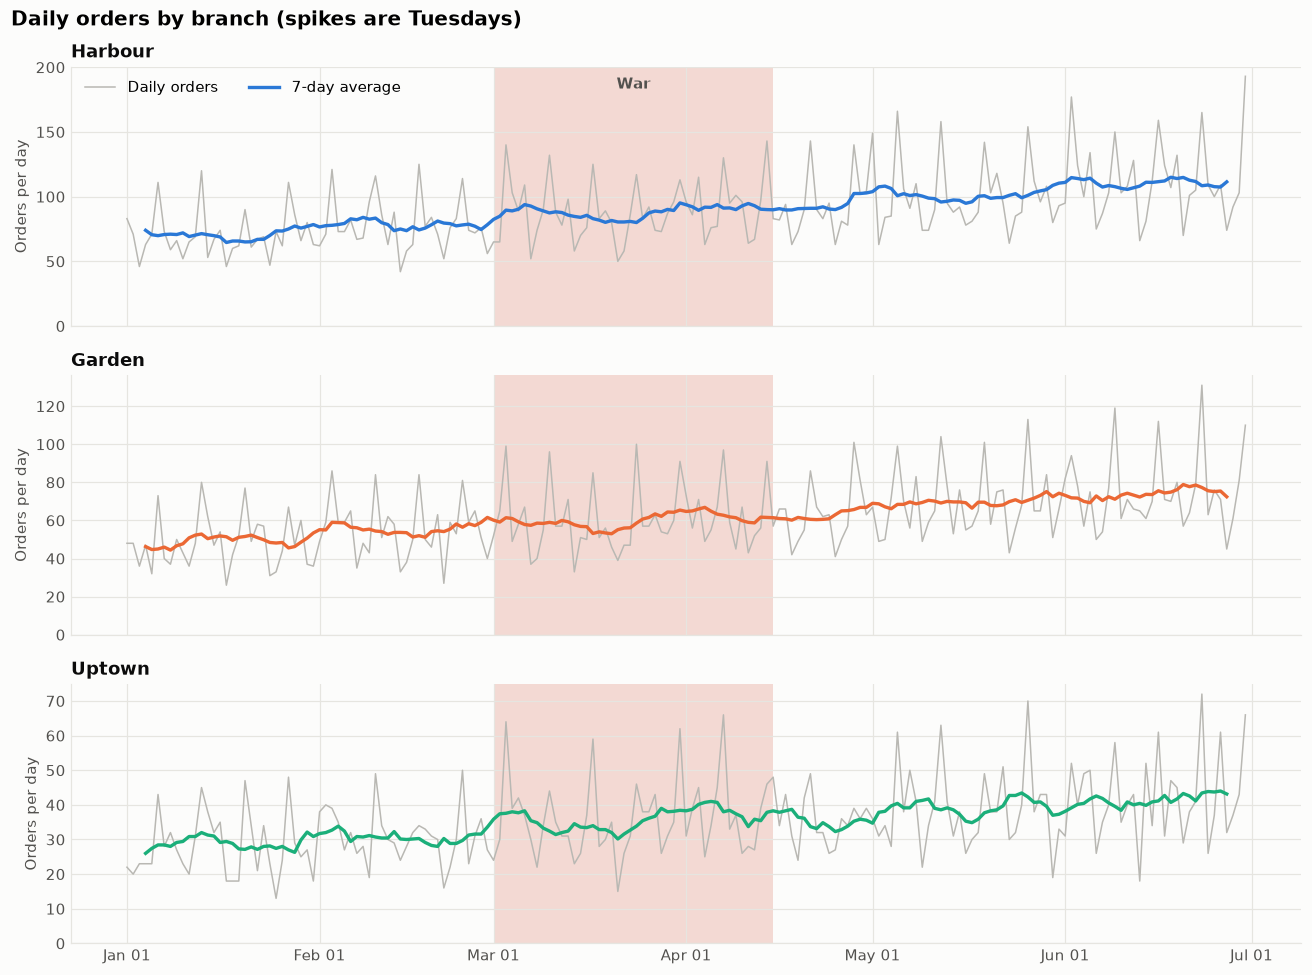

In [4]:
daily = (orders.groupby(["date", "branch"]).size().unstack()[BRANCHES])

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, b in zip(axes, BRANCHES):
    shade_war(ax, label=(b == BRANCHES[0]))
    ax.plot(daily.index, daily[b], color=MUTED, lw=1, label="Daily orders")
    ax.plot(daily.index, daily[b].rolling(7, center=True).mean(), color=BRANCH_COLORS[b], lw=2.2,
            label="7-day average")
    ax.set_ylim(0)
    ax.set_ylabel("Orders per day")
    ax.set_title(b)
axes[0].legend(loc="upper left", ncols=2)
fig.suptitle("Daily orders by branch (spikes are Tuesdays)", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**Takeaway:** none of the three branches shows a dip when the war starts on Mar 1 or a jump when the ceasefire begins on Apr 16. Each one keeps climbing at roughly the same pace throughout.

## 4. Trend-adjusted effect by branch

Sales were already growing week after week before the war. To ask whether the war **pushed sales below where they were heading**, for each branch we:
1. fit a simple model on **pre-war days only**: daily orders = growth trend + weekday effect (this captures the Tuesday spike and weak weekends);
2. project that model forward to get the **expected** orders if the pre-war pattern had simply continued;
3. compare **actual vs expected** in each period.

If the war hurt a branch, its actual orders during the war should fall clearly below the expected line.

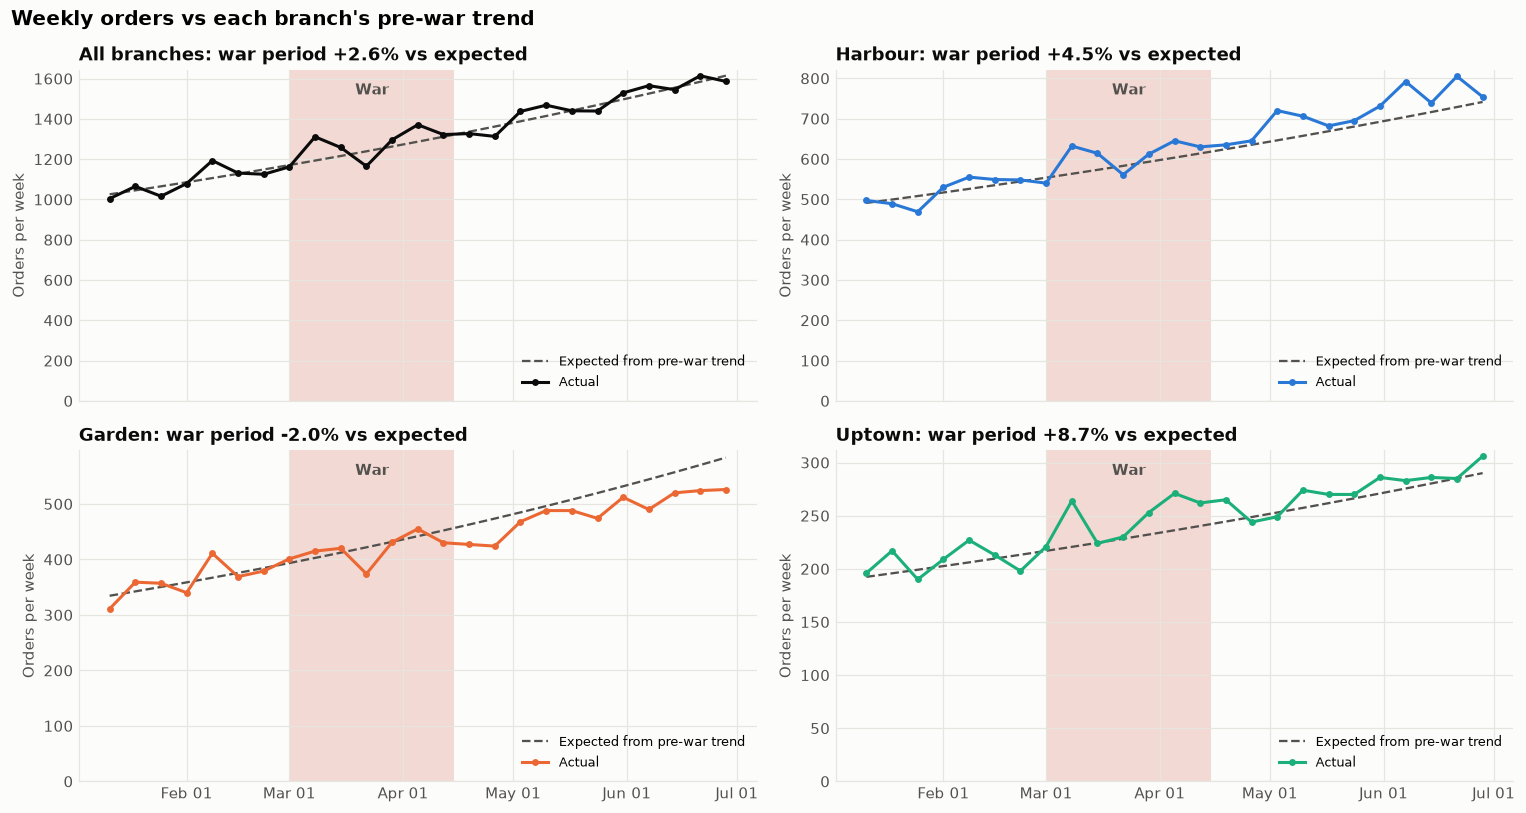

,Before the war,War,After the ceasefire
All branches,+0.3%,+2.6%,+0.6%
Harbour,+0.6%,+4.5%,+5.7%
Garden,+0.9%,-2.0%,-6.7%
Uptown,+1.7%,+8.7%,+2.8%


In [5]:
def fit_expected(daily_orders):
    """Fit log(orders) = trend + weekday on pre-war days; return expected orders for every day."""
    t = (daily_orders.index - daily_orders.index[0]).days.to_numpy()
    dow = pd.get_dummies(daily_orders.index.dayofweek, drop_first=True).to_numpy(float)
    X = np.column_stack([np.ones(len(t)), t, dow])
    pre = daily_orders.index < WAR_START
    beta, *_ = np.linalg.lstsq(X[pre], np.log(daily_orders.to_numpy()[pre]), rcond=None)
    return pd.Series(np.exp(X @ beta), index=daily_orders.index)


daily_all = daily.sum(axis=1).rename("All branches")
series = {"All branches": daily_all, **{b: daily[b] for b in BRANCHES}}
effect = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
for ax, (name, s) in zip(axes.flat, series.items()):
    exp = fit_expected(s)
    p = period_of(s.index)
    effect[name] = s.groupby(p, observed=True).sum() / exp.groupby(p, observed=True).sum() - 1
    wk = pd.DataFrame({"actual": s, "expected": exp}).resample("W-SUN").sum().iloc[1:-1]  # full weeks only
    shade_war(ax)
    ax.plot(wk.index, wk["expected"], color=INK2, lw=1.5, ls="--", label="Expected from pre-war trend")
    ax.plot(wk.index, wk["actual"], color=BRANCH_COLORS.get(name, INK), marker="o", ms=3.5, label="Actual")
    ax.set_ylim(0)
    ax.set_title(f"{name}: war period {effect[name]['War']:+.1%} vs expected")
    ax.set_ylabel("Orders per week")
    ax.legend(loc="lower right", fontsize=8.5)
fig.suptitle("Weekly orders vs each branch's pre-war trend", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

pd.DataFrame(effect).T.style.format("{:+.1%}").set_caption("Actual vs expected orders")

**Takeaway**
- **All branches together:** about **+3% above** the pre-war trend during the war, and on trend after the ceasefire. No negative war effect.
- **Harbour (+4.5%) and Uptown (+8.7%)** ran above their trends during the war.
- **Garden was slightly below its trend (-2%)**, and it fell further behind *after* the ceasefire (-7%). Because the gap grew after the fighting paused, it looks more like Garden's own growth slowing than a war effect. A single branch has fewer orders per day, so its model is noisier; treat this as a flag, not a conclusion.

## 5. Behavior by branch: time of day, dine-in vs takeaway, product mix

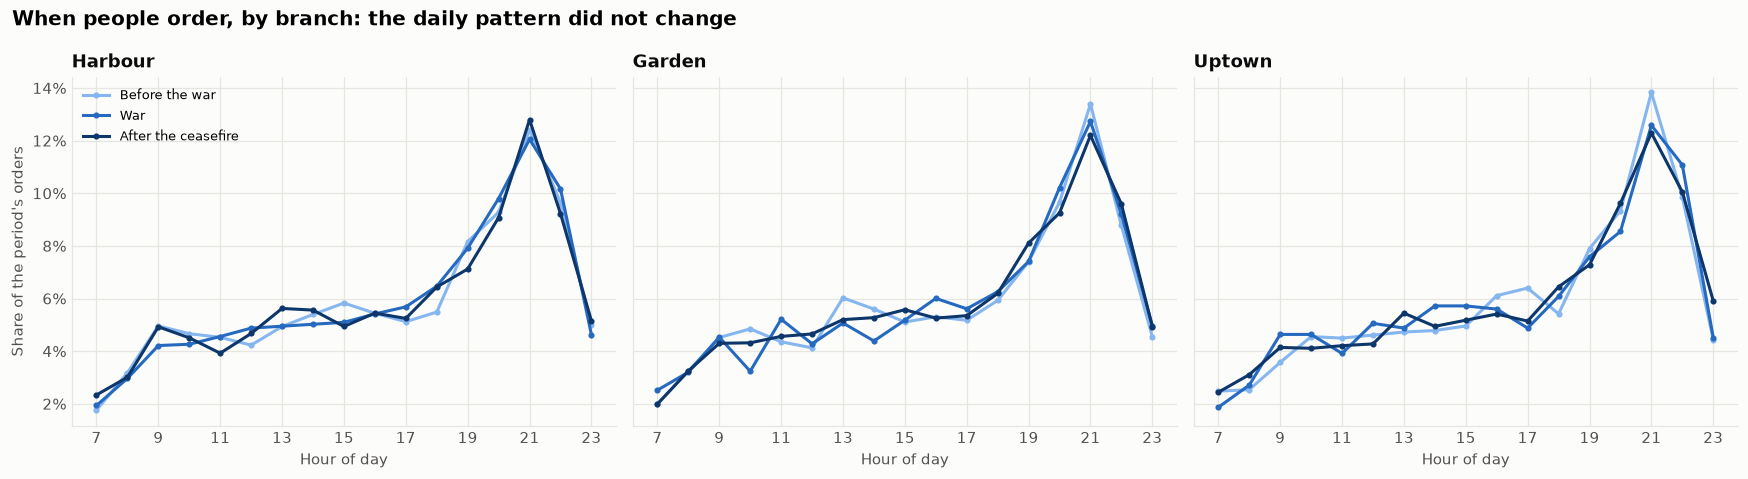

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, b in zip(axes, BRANCHES):
    o = orders[orders["branch"] == b]
    mix = pd.crosstab(o["hour"], o["period"], normalize="columns")[PERIODS]
    for p in PERIODS:
        ax.plot(mix.index, mix[p], color=PERIOD_COLORS[p], marker="o", ms=3, label=p)
    ax.set_title(b)
    ax.set_xticks(mix.index[::2])
    ax.set_xlabel("Hour of day")
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylabel("Share of the period's orders")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("When people order, by branch: the daily pattern did not change", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

In [7]:
behavior = headlines.loc[(BRANCHES, ["takeaway_share", "evening_share", "aov", "items_per_order"]), PERIODS]
behavior.style.format("{:.2f}")

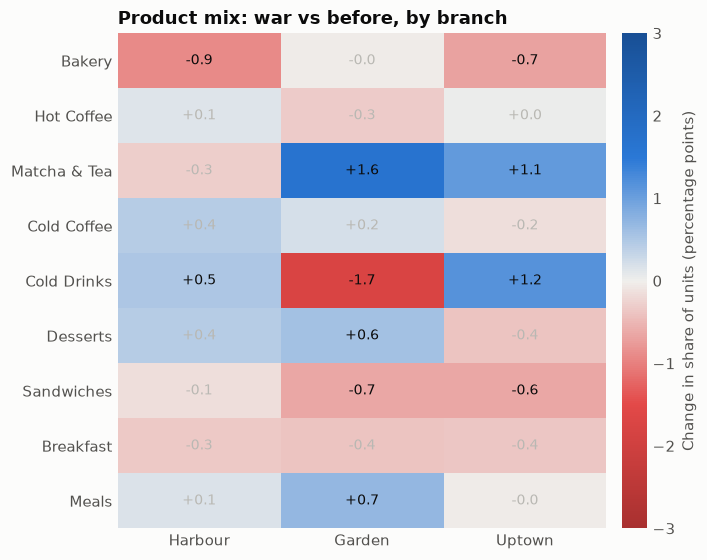

In [8]:
# Change in each category's share of units, war vs before, in percentage points
mix = pd.crosstab([df["Branch"], df["Category"]], df["period"], values=df["Quantity"], aggfunc="sum")
mix = mix / mix.groupby(level=0).transform("sum")
change = (mix["War"] - mix["Before the war"]).unstack(0)[BRANCHES] * 100
change = change.loc[mix["Before the war"].groupby(level=1).mean().sort_values(ascending=False).index]

DIV = LinearSegmentedColormap.from_list("div", ["#a8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])
lim = 3  # +/- 3 percentage points
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(change.values, cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(BRANCHES)), BRANCHES)
ax.set_yticks(range(len(change)), change.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(change.shape[0]):
    for j in range(change.shape[1]):
        v = change.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", color=INK if abs(v) >= 0.5 else MUTED, fontsize=9)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
cb.set_label("Change in share of units (percentage points)", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Product mix: war vs before, by branch")
plt.tight_layout()
plt.show()

**Takeaway:** in every branch, none of the behavior a war would typically change moved.
- **Time of day:** the 21:00 peak held at all three branches, and the evening share stayed at about 50%. Fear or curfews would usually push visits earlier.
- **Takeaway share** stayed at about 40-42% at every branch. People staying home more would usually push it up.
- **Product mix** shifted by less than 2 percentage points in any category at any branch. The largest moves were at Garden (Matcha & Tea +1.6, Cold Drinks -1.7), which is small and looks like normal variation. There was no shift toward cheaper items.

## 6. Customers by branch

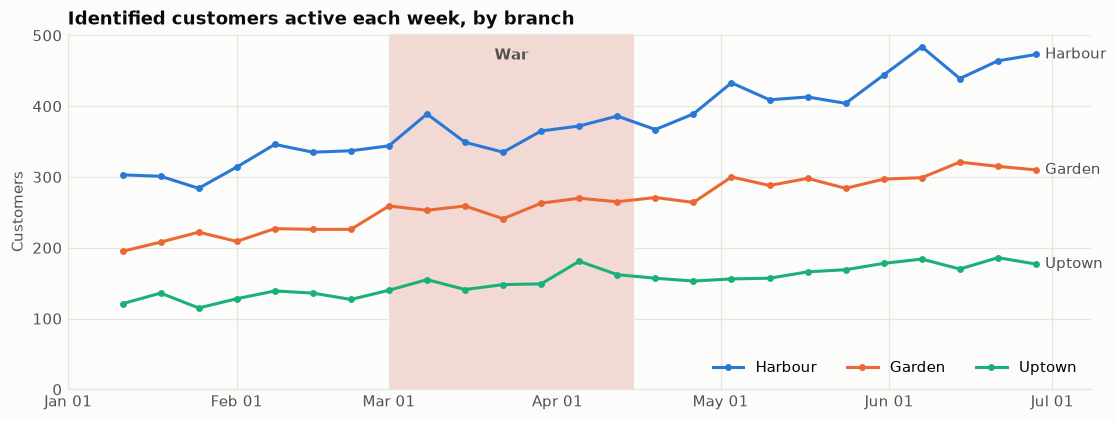

,Before the war,War,After the ceasefire,War vs before
branch,,,,
Harbour,320,366,429,+14.2%
Garden,222,258,295,+16.7%
Uptown,130,156,168,+19.8%


In [9]:
known = orders.dropna(subset=["customer"])
weekly_active = (known.set_index("date").groupby("branch").resample("W-SUN")["customer"].nunique()
                 .unstack(0)[BRANCHES].iloc[1:-1])

fig, ax = plt.subplots(figsize=(12, 4.2))
shade_war(ax)
for b in BRANCHES:
    ax.plot(weekly_active.index, weekly_active[b], color=BRANCH_COLORS[b], marker="o", ms=3.5, label=b)
    ax.annotate(b, (weekly_active.index[-1], weekly_active[b].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK2)
ax.set_ylim(0)
ax.margins(x=0.06)
ax.set_ylabel("Customers")
ax.set_title("Identified customers active each week, by branch")
ax.legend(loc="lower right", ncols=3)
plt.show()

# Average over full weeks; each week (Mon-Sun) is assigned to the period its Thursday falls in
cust = weekly_active.groupby(period_of(weekly_active.index - pd.Timedelta(days=3)), observed=True).mean().T
cust["War vs before"] = cust["War"] / cust["Before the war"] - 1
cust.style.format("{:,.0f}").format("{:+.1%}", subset=["War vs before"]).set_caption(
    "Average identified customers per week")

**Takeaway:** the number of identified customers visiting each week kept rising through the war at every branch: Harbour +14%, Garden +17%, Uptown +20% compared with before the war. No branch lost its regulars. Most customers use two or three branches (see `01_eda`), so if one area had become hard to reach you might expect visits to shift between branches. That didn't happen.

## 7. Conclusion by branch

**The data shows no measurable negative effect of the war at any branch.**

| | Harbour | Garden | Uptown |
|---|---|---|---|
| Orders per day, war vs before | +20% | +17% | +23% |
| Orders vs pre-war trend, during war | +4.5% | -2.0% | +8.7% |
| Average order value | Flat | Flat | Flat (-2%) |
| Time of day, takeaway, product mix | Unchanged | Unchanged | Unchanged |
| Active customers per week | Rising | Rising | Rising |
| Verdict | No war effect | Slightly below trend; widened after the ceasefire, so likely unrelated to the war | No war effect |

**How to interpret this:**
1. **The dataset is synthetic** (IDs start with `SYN-`). It was almost certainly generated with a smooth growth trend and no war shock built in. Whatever this shows, it doesn't tell us how a real café in Lebanon was affected.
2. **If the team wants to use the war in the pitch**, frame it as *resilience*: "every branch kept growing through the war and the ceasefire". Don't claim a war impact the data doesn't show.
3. **Garden is worth watching**, but for its own reasons: its growth is slowing, and it already has the cost problem found in `01_eda`.
4. **What real data would usually show** in a conflict, for comparison: a drop in evening and dine-in visits, a shift toward takeaway or delivery, lower spend per order, rising costs from supply disruption, and differences between branches depending on how close they are to affected areas. None of these appear here.

To test a different end date (for example the Jun 4 conditional ceasefire), change `WAR_END` in the first code cell and re-run all cells.